# 10주차 Q9 · Q10 — Git + 인공지능 모델

- 문항 설명과 기대 출력은 **`10주차_Q9_Q10_문제.pdf`** 를 참고하세요.
- 이 노트북을 저장소의 `main.ipynb` 로 두고, 아래 단계에 맞추어 작성하며 **단계마다 커밋**합니다.
- 각 셀은 **실행하여 출력이 저장된 상태**로 커밋해야 합니다.
- 채점은 **PDF 의 참고 이미지와 셀 출력을 대조**하여 이루어집니다.
    출력이 없거나 참고 이미지와 다르면 0점입니다.
- **merge 를 마친 뒤 `main` 브랜치의 이 파일을 내려받아 과제와 함께 제출**합니다.
    저장소 링크만으로는 제출이 완료되지 않습니다.
- 제출한 파일과 **저장소의 내용이 반드시 일치**해야 합니다.
- **저장소를 확인할 수 없으면 Q9 · Q10 은 0점**입니다.

| 단계 | 브랜치 | Commit Message |
|---|---|---|
| 1단계 (Q9) | `main` | `Step1` |
| 2단계 (Q9) | `prep_branch` | `Step2` |
| 3단계 (Q10) | `fin_branch` | `Step3` → `main` 에 merge |

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:

from google.colab import drive
from pathlib import Path
import shutil

drive.mount('/content/drive')

# 여기에 드라이브에서 복사한 실제 CSV 경로 붙여넣기
csv_path = Path('/content/drive/MyDrive/메타코드/student_dropout.csv')

assert csv_path.is_file(), "CSV 파일 경로를 확인하세요."

# 기존 Step1 코드의 상대경로에 맞게 파일 복사
shutil.copy2(csv_path, '/content/student_dropout.csv')

print("데이터 준비 완료")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
데이터 준비 완료


In [4]:
# 불필요한 출력을 없애기 위한 코드입니다.
# 문제풀이와는 무관합니다.
import warnings
warnings.filterwarnings('ignore')

## Step1 — 라이브러리 불러오기, 데이터 읽기

In [5]:
# 데이터 읽기용 코드셀입니다.

import pandas as pd
print('='*20, 'student_dropout.csv 데이터 정보입니다.', '='*20)
tmp_df = pd.read_csv('./student_dropout.csv')
display(tmp_df.shape)
display(tmp_df.columns)
display(tmp_df[['Age at enrollment', 'Admission grade', 'Scholarship holder', 'Target']].head())

==================== student_dropout.csv 데이터 정보입니다. ====================


(4424, 37)

Index(['Marital status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd s

,Age at enrollment,Admission grade,Scholarship holder,Target
0,20,127.3,0,Dropout
1,19,142.5,0,Graduate
2,19,124.8,0,Dropout
3,20,119.6,0,Graduate
4,45,141.5,0,Graduate


## Step2 — 데이터 전처리

<b>코드 Cell</b>
- features 와 target 으로 데이터를 분리합니다.
- features 는 <b>크기만</b>, target 은 <b>크기와 앞부분</b>을 출력합니다.

In [6]:

features = tmp_df.drop(columns=['Target']).select_dtypes(include='number')
target = tmp_df['Target']

print('='*20, 'features 정보입니다.', '='*20)
print(features.shape)

print('='*20, 'target 정보입니다.', '='*20)
print(target.shape)
print(target.head())


==================== features 정보입니다. ====================
(4424, 36)
==================== target 정보입니다. ====================
(4424,)
0     Dropout
1    Graduate
2     Dropout
3    Graduate
4    Graduate
Name: Target, dtype: object


<b>코드 Cell</b>
- features 와 target 데이터를 train_test_split 을 통해 분리합니다.
- test_size = 0.2 로 설정하고 random_state = 42 로 설정합니다.

In [7]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=42
)

print('='*20, '분할 이후 train 데이터 크기입니다.', '='*20)
print(X_train.shape)
print(y_train.shape)

print('='*20, '분할 이후 test 데이터 크기입니다.', '='*20)
print(X_test.shape)
print(y_test.shape)

print('='*20, 'train 데이터와 test 데이터 비율 계산 결과입니다.', '='*20)
print(len(X_train) / len(features))
print(len(X_test) / len(features))


==================== 분할 이후 train 데이터 크기입니다. ====================
(3539, 36)
(3539,)
==================== 분할 이후 test 데이터 크기입니다. ====================
(885, 36)
(885,)
==================== train 데이터와 test 데이터 비율 계산 결과입니다. ====================
0.7999547920433996
0.20004520795660036


<b>코드 Cell</b>
- target 데이터에 대한 LabelEncoding 과정을 수행합니다.
- <b>이 셀에서는 출력이 발생하지 않습니다.</b>

In [8]:

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train_before = y_train.copy()

encoder.fit(target)

y_train = encoder.transform(y_train)
y_test = encoder.transform(y_test)


<b>코드 Cell</b>
- hist 시각화를 통해 Label Encoding 전후의 모습을 확인합니다.

==================== LabelEncoding 이전의 분포입니다. ====================


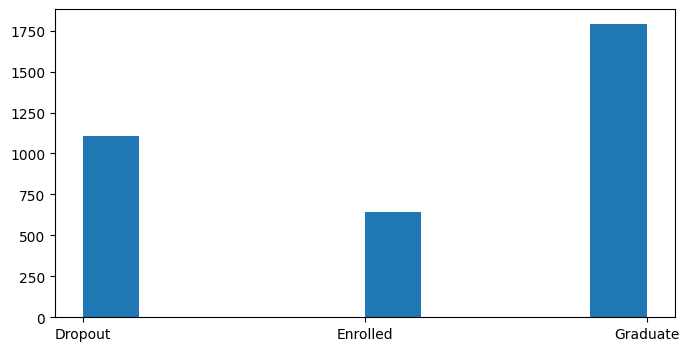

==================== LabelEncoding 이후의 분포입니다. ====================


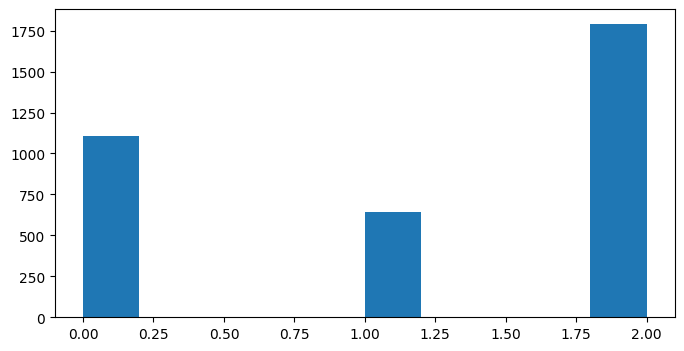

In [10]:

import matplotlib.pyplot as plt

print('='*20, 'LabelEncoding 이전의 분포입니다.', '='*20)

plt.figure(figsize=(8, 4))
plt.hist(y_train_before)
plt.show()

print('='*20, 'LabelEncoding 이후의 분포입니다.', '='*20)

plt.figure(figsize=(8, 4))
plt.hist(y_train)
plt.show()


## Step3 — 모델 학습

<b>코드 Cell</b>
- 모델을 선언하고 학습시킨 뒤, 예측과 평가 지표 계산까지 수행합니다.
- <b>이 셀에서는 출력이 발생하지 않습니다.</b>

In [11]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 모델 선언
model = RandomForestClassifier(random_state=42)

# 모델 학습
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)

# 평가 지표 계산
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
)


<b>코드 Cell</b>
- 앞 셀에서 계산한 정확도와 classification_report 를 출력합니다.

In [12]:

print('='*20, 'accuracy 결과입니다.', '='*20)
print(accuracy)

print('='*20, 'classification_report 결과입니다.', '='*20)
print(report)


==================== accuracy 결과입니다. ====================
0.7604519774011299
==================== classification_report 결과입니다. ====================
              precision    recall  f1-score   support

     Dropout       0.85      0.77      0.81       316
    Enrolled       0.49      0.30      0.37       151
    Graduate       0.76      0.92      0.83       418

    accuracy                           0.76       885
   macro avg       0.70      0.66      0.67       885
weighted avg       0.75      0.76      0.74       885



<b>코드 Cell</b>
- 학습한 모델이 중요하게 본 feature 를 정리하여 출력합니다.

In [13]:

feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values('importance', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

feature_importance['importance'] = (
    feature_importance['importance'].round(4)
)

print('='*20, 'feature 중요도 상위 10개입니다.', '='*20)
display(feature_importance)


==================== feature 중요도 상위 10개입니다. ====================


,feature,importance
0,Curricular units 2nd sem (approved),0.1311
1,Curricular units 2nd sem (grade),0.1112
2,Curricular units 1st sem (approved),0.0973
3,Curricular units 1st sem (grade),0.0635
4,Curricular units 2nd sem (evaluations),0.0437
5,Tuition fees up to date,0.0432
6,Admission grade,0.0408
7,Previous qualification (grade),0.0381
8,Curricular units 1st sem (evaluations),0.0374
9,Age at enrollment,0.0356


<b>코드 Cell — 제출 확인</b>

- 제출 시각과 **지금까지의 커밋 이력**을 출력합니다.
- <b>이 셀은 `Step3` 을 커밋하기 직전에 실행</b>하세요. `Step1` · `Step2` 의 커밋이 출력됩니다.
- 여기에 출력된 커밋과 <b>Q9 캡처 화면의 커밋이 서로 일치</b>해야 정답으로 인정됩니다.
- 출력값은 사람마다 다릅니다. 참고 이미지를 제공하지 않으니 <b>출력 형태만</b> 맞추면 됩니다.

In [16]:
import subprocess
from datetime import datetime

print('='*20, '제출 시각입니다.', '='*20)
print(datetime.now())

print('='*20, '현재까지의 커밋 이력입니다.', '='*20)
log = subprocess.run(['git', 'log', '--oneline'],
                     capture_output=True, text=True, encoding='utf-8')
print(log.stdout)

==================== 제출 시각입니다. ====================
2026-11-19 12:01:30.320570
==================== 현재까지의 커밋 이력입니다. ====================
5f83968 step2
1307f45 Step1

